In [2]:
import pandas as pd
import numpy as np
import seaborn
import matplotlib.pyplot as plt

Append Sales

In [3]:
sales_1997 = pd.read_csv(r"E:\Current courses\NTI\grad project\company\Sales\Sales 1997.csv")
sales_1998 = pd.read_csv(r"E:\Current courses\NTI\grad project\company\Sales\Sales 1998.csv")
sales_1999 = pd.read_csv(r"E:\Current courses\NTI\grad project\company\Sales\Sales 1999.csv")

sales = pd.concat([sales_1997, sales_1998, sales_1999],axis=0, ignore_index=True)
sales

,transaction_date,stock_date,product_id,customer_id,store_id,quantity,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,1/1/1997,12/31/1996,869,3449,6,5,NaN,NaN,NaN,NaN,NaN
1,1/1/1997,12/31/1996,1472,3449,6,3,NaN,NaN,NaN,NaN,NaN
2,1/1/1997,12/28/1996,76,3449,6,4,NaN,NaN,NaN,NaN,NaN
3,1/1/1997,12/26/1996,320,3449,6,3,NaN,NaN,NaN,NaN,NaN
4,1/1/1997,12/25/1996,4,3449,6,4,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
356552,3/24/1999,12/29/1997,1516,7043,22,5,NaN,NaN,NaN,NaN,NaN
356553,3/12/1999,12/26/1997,1050,7043,22,10,NaN,NaN,NaN,NaN,NaN
356554,11/26/1999,12/23/1997,1471,7043,22,1,NaN,NaN,NaN,NaN,NaN
356555,6/13/1999,12/29/1997,803,2145,1,5,NaN,NaN,NaN,NaN,NaN


In [4]:
sales = sales.loc[:, ~sales.columns.str.contains('^Unnamed')]

In [5]:
sales

,transaction_date,stock_date,product_id,customer_id,store_id,quantity
0,1/1/1997,12/31/1996,869,3449,6,5
1,1/1/1997,12/31/1996,1472,3449,6,3
2,1/1/1997,12/28/1996,76,3449,6,4
3,1/1/1997,12/26/1996,320,3449,6,3
4,1/1/1997,12/25/1996,4,3449,6,4
...,...,...,...,...,...,...
356552,3/24/1999,12/29/1997,1516,7043,22,5
356553,3/12/1999,12/26/1997,1050,7043,22,10
356554,11/26/1999,12/23/1997,1471,7043,22,1
356555,6/13/1999,12/29/1997,803,2145,1,5


Check data types

In [6]:
sales.dtypes

transaction_date    object
stock_date          object
product_id           int64
customer_id          int64
store_id             int64
quantity             int64
dtype: object

In [7]:
sales.loc[:, 'transaction_date'] = pd.to_datetime(sales['transaction_date'], errors='coerce')

In [8]:
sales.loc[:, 'stock_date'] = pd.to_datetime(sales['stock_date'], errors='coerce')

In [9]:
sales.dtypes

transaction_date    object
stock_date          object
product_id           int64
customer_id          int64
store_id             int64
quantity             int64
dtype: object

In [10]:
sales[sales['transaction_date'].isna()]


,transaction_date,stock_date,product_id,customer_id,store_id,quantity


In [11]:
customers = pd.read_csv(r"E:\Current courses\NTI\grad project\company\Customers.csv")
stores = pd.read_csv(r"E:\Current courses\NTI\grad project\company\Stores.csv")
products = pd.read_csv(r"E:\Current courses\NTI\grad project\company\Products.csv")
region = pd.read_csv(r"E:\Current courses\NTI\grad project\company\Region.csv")
returns = pd.read_excel(r"E:\Current courses\NTI\grad project\company\Returns.xlsx")

In [12]:
customers.dtypes

customer_id                 int64
customer_acct_num           int64
first_name                 object
last_name                  object
customer_address           object
customer_city              object
customer_state_province    object
customer_postal_code        int64
customer_country           object
birthdate                  object
marital_status             object
yearly_income              object
gender                     object
total_children              int64
num_children_at_home        int64
education                  object
acct_open_date             object
member_card                object
occupation                 object
homeowner                  object
dtype: object

In [13]:
customers['birthdate'] = pd.to_datetime(customers['birthdate'], errors='coerce')
customers['acct_open_date'] = pd.to_datetime(customers['acct_open_date'], errors='coerce')

In [14]:
stores.dtypes

store_id                 int64
region_id                int64
store_type              object
store_name              object
store_street_address    object
store_city              object
store_state             object
store_country           object
store_phone             object
first_opened_date       object
last_remodel_date       object
total_sqft               int64
grocery_sqft             int64
dtype: object

In [15]:
stores['first_opened_date'] = pd.to_datetime(
    stores['first_opened_date'], errors='coerce'
)

stores['last_remodel_date'] = pd.to_datetime(
    stores['last_remodel_date'], errors='coerce'
)


In [16]:
products.dtypes

product_id                int64
product_brand            object
product_name             object
product_sku               int64
product_retail_price    float64
product_cost            float64
product_weight          float64
recyclable              float64
low_fat                 float64
dtype: object

In [17]:
products['recyclable'] = products['recyclable'].astype(bool)
products['low_fat'] = products['low_fat'].astype(bool)
products['product_sku'] = products['product_sku'].astype(str)

In [18]:
region.dtypes

region_id          int64
sales_district    object
sales_region      object
dtype: object

In [19]:
returns.dtypes

return_date    datetime64[ns]
product_id              int64
store_id                int64
quantity                int64
dtype: object

In [20]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 356557 entries, 0 to 356556
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   transaction_date  356557 non-null  object
 1   stock_date        356557 non-null  object
 2   product_id        356557 non-null  int64 
 3   customer_id       356557 non-null  int64 
 4   store_id          356557 non-null  int64 
 5   quantity          356557 non-null  int64 
dtypes: int64(4), object(2)
memory usage: 16.3+ MB


In [21]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10281 entries, 0 to 10280
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customer_id              10281 non-null  int64         
 1   customer_acct_num        10281 non-null  int64         
 2   first_name               10281 non-null  object        
 3   last_name                10280 non-null  object        
 4   customer_address         10281 non-null  object        
 5   customer_city            10281 non-null  object        
 6   customer_state_province  10281 non-null  object        
 7   customer_postal_code     10281 non-null  int64         
 8   customer_country         10281 non-null  object        
 9   birthdate                10281 non-null  datetime64[ns]
 10  marital_status           10281 non-null  object        
 11  yearly_income            10281 non-null  object        
 12  gender                   10281 n

In [22]:
customers = customers.dropna(subset=["last_name"], axis=0, how="any")

In [23]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10280 entries, 0 to 10280
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customer_id              10280 non-null  int64         
 1   customer_acct_num        10280 non-null  int64         
 2   first_name               10280 non-null  object        
 3   last_name                10280 non-null  object        
 4   customer_address         10280 non-null  object        
 5   customer_city            10280 non-null  object        
 6   customer_state_province  10280 non-null  object        
 7   customer_postal_code     10280 non-null  int64         
 8   customer_country         10280 non-null  object        
 9   birthdate                10280 non-null  datetime64[ns]
 10  marital_status           10280 non-null  object        
 11  yearly_income            10280 non-null  object        
 12  gender                   10280 non-nu

In [24]:
stores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   store_id              24 non-null     int64         
 1   region_id             24 non-null     int64         
 2   store_type            24 non-null     object        
 3   store_name            24 non-null     object        
 4   store_street_address  24 non-null     object        
 5   store_city            24 non-null     object        
 6   store_state           24 non-null     object        
 7   store_country         24 non-null     object        
 8   store_phone           24 non-null     object        
 9   first_opened_date     24 non-null     datetime64[ns]
 10  last_remodel_date     24 non-null     datetime64[ns]
 11  total_sqft            24 non-null     int64         
 12  grocery_sqft          24 non-null     int64         
dtypes: datetime64[ns](2), 

In [25]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1560 entries, 0 to 1559
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   product_id            1560 non-null   int64  
 1   product_brand         1560 non-null   object 
 2   product_name          1560 non-null   object 
 3   product_sku           1560 non-null   object 
 4   product_retail_price  1560 non-null   float64
 5   product_cost          1560 non-null   float64
 6   product_weight        1560 non-null   float64
 7   recyclable            1560 non-null   bool   
 8   low_fat               1560 non-null   bool   
dtypes: bool(2), float64(3), int64(1), object(3)
memory usage: 88.5+ KB


In [26]:
products = products.drop(columns=["low_fat","recyclable"], axis=1)
products

,product_id,product_brand,product_name,product_sku,product_retail_price,product_cost,product_weight
0,1,Washington,Washington Berry Juice,90748583674,2.85,0.94,8.39
1,2,Washington,Washington Mango Drink,96516502499,0.74,0.26,7.42
2,3,Washington,Washington Strawberry Drink,58427771925,0.83,0.40,13.10
3,4,Washington,Washington Cream Soda,64412155747,3.64,1.64,10.60
4,5,Washington,Washington Diet Soda,85561191439,2.19,0.77,6.66
...,...,...,...,...,...,...,...
1555,1556,CDR,CDR Creamy Peanut Butter,29538288712,2.65,1.14,6.94
1556,1557,CDR,CDR Strawberry Preserves,50687324404,1.20,0.48,15.40
1557,1558,CDR,CDR Extra Chunky Peanut Butter,84930775761,2.16,0.82,11.50
1558,1559,CDR,CDR Apple Preserves,75317577719,1.62,0.62,21.00


In [27]:
region.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109 entries, 0 to 108
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   region_id       109 non-null    int64 
 1   sales_district  109 non-null    object
 2   sales_region    109 non-null    object
dtypes: int64(1), object(2)
memory usage: 2.7+ KB


In [28]:
returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7087 entries, 0 to 7086
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   return_date  7087 non-null   datetime64[ns]
 1   product_id   7087 non-null   int64         
 2   store_id     7087 non-null   int64         
 3   quantity     7087 non-null   int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 221.6 KB


dealing with duplicates

In [29]:
sales = sales.drop_duplicates()
customers = customers.drop_duplicates()
products = products.drop_duplicates()
stores = stores.drop_duplicates()
region = region.drop_duplicates()
returns = returns.drop_duplicates()

Denormalized table

In [30]:
sales = sales.merge(customers, 
                    on='customer_id', 
                    how='left')

In [31]:
sales = sales.merge(products, 
                    on='product_id', 
                    how='left')


In [32]:
sales = sales.merge(stores, 
                    on='store_id', 
                    how='left')

In [33]:
sales = sales.merge(region, on='region_id', how='left')

In [34]:
sales = sales.merge(returns,
                    on='product_id',
                    how='left')

In [35]:
sales.shape

(1632654, 48)

In [36]:
sales.isnull().sum()

transaction_date              0
stock_date                    0
product_id                    0
customer_id                   0
store_id_x                    0
quantity_x                    0
customer_acct_num           215
first_name                  215
last_name                   215
customer_address            215
customer_city               215
customer_state_province     215
customer_postal_code        215
customer_country            215
birthdate                   215
marital_status              215
yearly_income               215
gender                      215
total_children              215
num_children_at_home        215
education                   215
acct_open_date              215
member_card                 215
occupation                  215
homeowner                   215
product_brand                 0
product_name                  0
product_sku                   0
product_retail_price          0
product_cost                  0
product_weight                0
region_i

In [37]:
sales

,transaction_date,stock_date,product_id,customer_id,store_id_x,quantity_x,customer_acct_num,first_name,last_name,customer_address,...,store_phone,first_opened_date,last_remodel_date,total_sqft,grocery_sqft,sales_district,sales_region,return_date,store_id_y,quantity_y
0,1997-01-01 00:00:00,1996-12-31 00:00:00,869,3449,6,5,2.750831e+10,Lana,Weis,9648 Maureen Circle,...,958-555-5002,1981-01-03,1991-03-13,23688,15337,Los Angeles,South West,1997-01-01,6.0,1.0
1,1997-01-01 00:00:00,1996-12-31 00:00:00,869,3449,6,5,2.750831e+10,Lana,Weis,9648 Maureen Circle,...,958-555-5002,1981-01-03,1991-03-13,23688,15337,Los Angeles,South West,1997-06-01,24.0,1.0
2,1997-01-01 00:00:00,1996-12-31 00:00:00,869,3449,6,5,2.750831e+10,Lana,Weis,9648 Maureen Circle,...,958-555-5002,1981-01-03,1991-03-13,23688,15337,Los Angeles,South West,1997-11-02,7.0,1.0
3,1997-01-01 00:00:00,1996-12-31 00:00:00,869,3449,6,5,2.750831e+10,Lana,Weis,9648 Maureen Circle,...,958-555-5002,1981-01-03,1991-03-13,23688,15337,Los Angeles,South West,1998-03-03,10.0,1.0
4,1997-01-01 00:00:00,1996-12-31 00:00:00,869,3449,6,5,2.750831e+10,Lana,Weis,9648 Maureen Circle,...,958-555-5002,1981-01-03,1991-03-13,23688,15337,Los Angeles,South West,1998-05-06,19.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1632649,1999-06-13 00:00:00,1997-12-29 00:00:00,803,2145,1,5,1.787307e+10,Sandra,Chumney,8475 Riverwood Circle,...,262-555-5124,1982-01-09,1990-12-05,23593,17475,Acapulco,Mexico West,1997-05-03,3.0,1.0
1632650,1999-06-13 00:00:00,1997-12-29 00:00:00,803,2145,1,5,1.787307e+10,Sandra,Chumney,8475 Riverwood Circle,...,262-555-5124,1982-01-09,1990-12-05,23593,17475,Acapulco,Mexico West,1997-06-11,11.0,1.0
1632651,1999-10-25 00:00:00,1997-12-28 00:00:00,646,2145,15,4,1.787307e+10,Sandra,Chumney,8475 Riverwood Circle,...,893-555-1024,1969-07-24,1973-10-19,21215,13305,Seattle,North West,1997-04-14,6.0,1.0
1632652,1999-10-25 00:00:00,1997-12-28 00:00:00,646,2145,15,4,1.787307e+10,Sandra,Chumney,8475 Riverwood Circle,...,893-555-1024,1969-07-24,1973-10-19,21215,13305,Seattle,North West,1998-01-10,16.0,1.0


In [38]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1632654 entries, 0 to 1632653
Data columns (total 48 columns):
 #   Column                   Non-Null Count    Dtype         
---  ------                   --------------    -----         
 0   transaction_date         1632654 non-null  object        
 1   stock_date               1632654 non-null  object        
 2   product_id               1632654 non-null  int64         
 3   customer_id              1632654 non-null  int64         
 4   store_id_x               1632654 non-null  int64         
 5   quantity_x               1632654 non-null  int64         
 6   customer_acct_num        1632439 non-null  float64       
 7   first_name               1632439 non-null  object        
 8   last_name                1632439 non-null  object        
 9   customer_address         1632439 non-null  object        
 10  customer_city            1632439 non-null  object        
 11  customer_state_province  1632439 non-null  object        
 12  

In [98]:
nulls = sales.isnull().sum().sort_values(ascending=False)
nulls[nulls > 0]

return_date    4573
dtype: int64

In [90]:
sales = sales.dropna(subset=['first_name'])

In [105]:
sales = sales.rename(columns={
    'quantity_x':'quantity_sold',
    'quantity_y':'quantity_returned'})

In [106]:
sales.columns

Index(['transaction_date', 'stock_date', 'product_id', 'customer_id',
       'store_id_x', 'quantity_sold', 'customer_acct_num', 'first_name',
       'last_name', 'customer_address', 'customer_city',
       'customer_state_province', 'customer_postal_code', 'customer_country',
       'birthdate', 'marital_status', 'yearly_income', 'gender',
       'total_children', 'num_children_at_home', 'education', 'acct_open_date',
       'member_card', 'occupation', 'homeowner', 'product_brand',
       'product_name', 'product_sku', 'product_retail_price', 'product_cost',
       'product_weight', 'region_id', 'store_type', 'store_name',
       'store_street_address', 'store_city', 'store_state', 'store_country',
       'store_phone', 'first_opened_date', 'last_remodel_date', 'total_sqft',
       'grocery_sqft', 'sales_district', 'sales_region', 'return_date',
       'store_id_y', 'quantity_returned'],
      dtype='object')

In [107]:
(sales['store_id_x'] == sales['store_id_y']).all()

np.False_

In [101]:
nulls = sales.isnull().sum().sort_values(ascending=False)
nulls[nulls > 0]

return_date    4573
dtype: int64

In [102]:
sales.shape

(1632439, 48)

correlation

In [103]:
num_cols = list(set(sales.describe().columns.to_list()))
cat_cols = list(set(sales.columns.to_list()))

In [104]:
corr_matrix = sales[num_cols].corr()

In [110]:
print(num_cols)

['return_date', 'grocery_sqft', 'customer_id', 'customer_postal_code', 'num_children_at_home', 'total_children', 'customer_acct_num', 'product_id', 'product_retail_price', 'last_remodel_date', 'first_opened_date', 'quantity_returned', 'store_id_y', 'quantity_sold', 'region_id', 'total_sqft', 'acct_open_date', 'product_cost', 'birthdate', 'product_weight', 'store_id_x']


<Axes: >

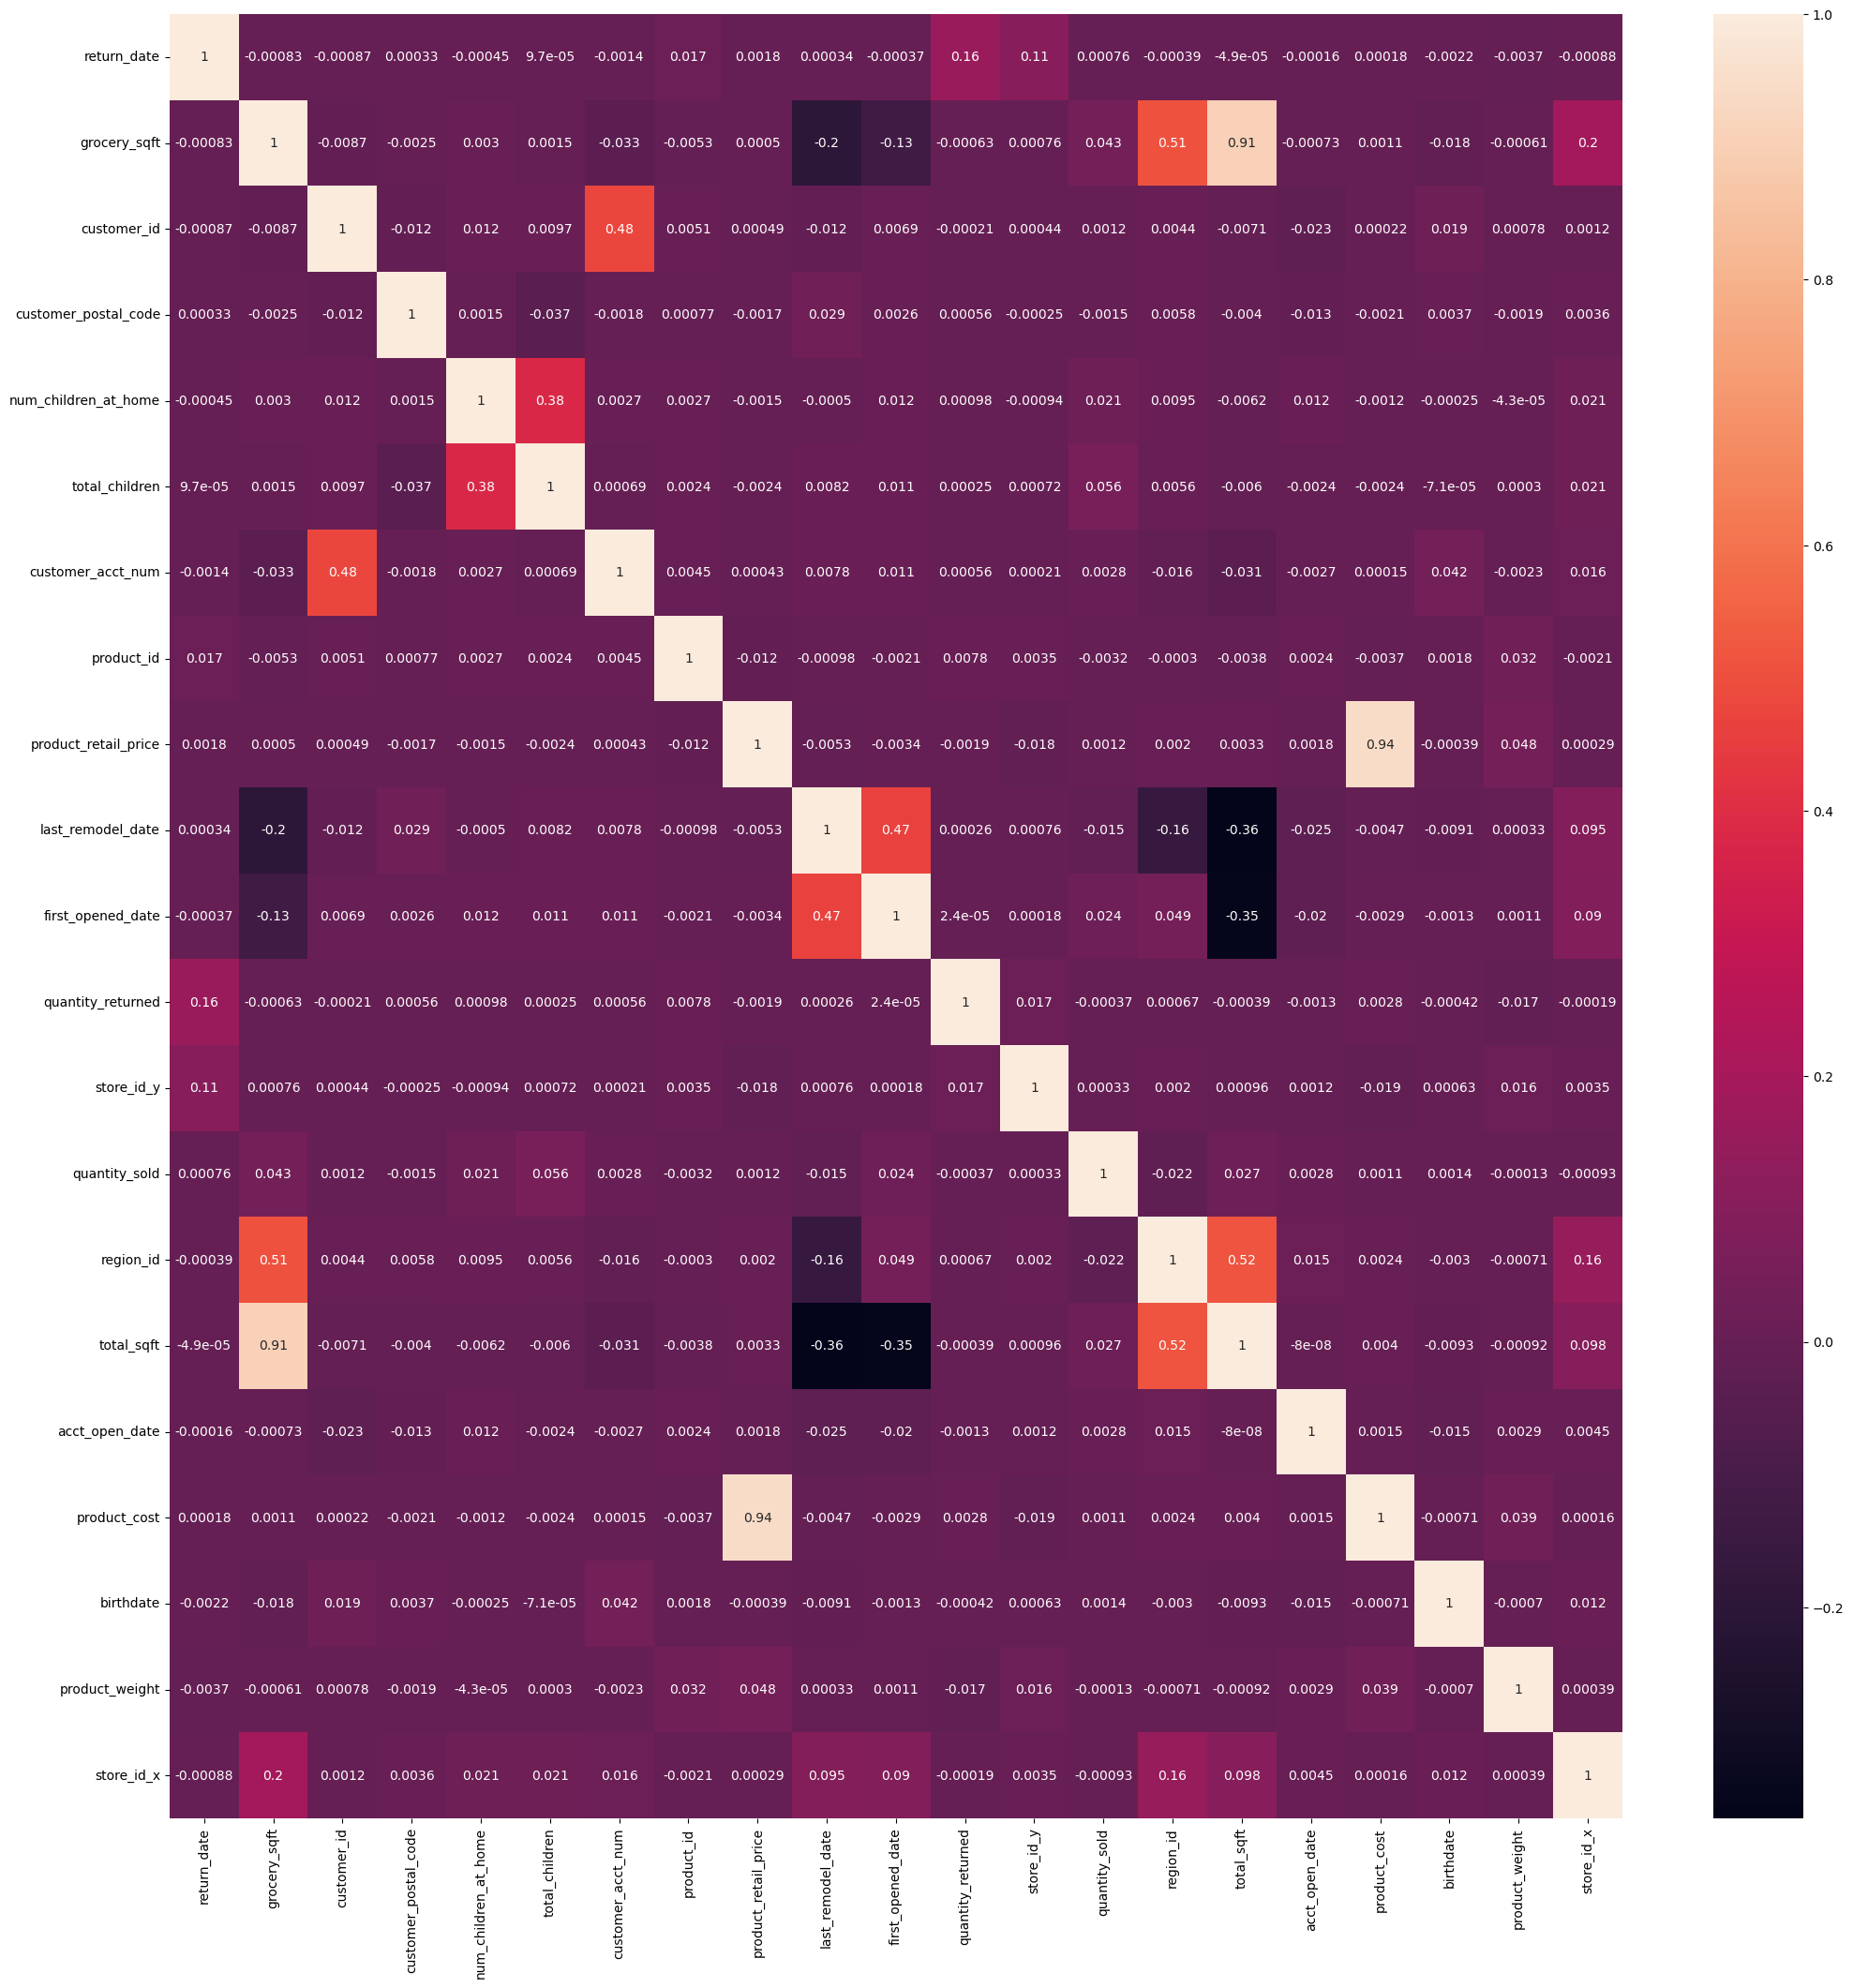

In [109]:
plt.figure(figsize=(25, 25))

seaborn.heatmap(corr_matrix, annot=True)

In [112]:
num_cols_without_resposne = list(set(num_cols) - set(["quantity_sold"]))
corr_matrix = sales[num_cols_without_resposne]
corr_matrix

,return_date,total_sqft,grocery_sqft,acct_open_date,customer_postal_code,customer_id,num_children_at_home,product_cost,total_children,customer_acct_num,birthdate,product_id,product_retail_price,last_remodel_date,product_weight,first_opened_date,quantity_returned,store_id_y,store_id_x,region_id
0,1997-01-01,23688,15337,1994-12-07,16093.0,3449,0.0,0.91,2.0,2.750831e+10,1979-11-26,869,2.12,1991-03-13,17.00,1981-01-03,1.0,6.0,6,47
1,1997-06-01,23688,15337,1994-12-07,16093.0,3449,0.0,0.91,2.0,2.750831e+10,1979-11-26,869,2.12,1991-03-13,17.00,1981-01-03,1.0,24.0,6,47
2,1997-11-02,23688,15337,1994-12-07,16093.0,3449,0.0,0.91,2.0,2.750831e+10,1979-11-26,869,2.12,1991-03-13,17.00,1981-01-03,1.0,7.0,6,47
3,1998-03-03,23688,15337,1994-12-07,16093.0,3449,0.0,0.91,2.0,2.750831e+10,1979-11-26,869,2.12,1991-03-13,17.00,1981-01-03,1.0,10.0,6,47
4,1998-05-06,23688,15337,1994-12-07,16093.0,3449,0.0,0.91,2.0,2.750831e+10,1979-11-26,869,2.12,1991-03-13,17.00,1981-01-03,2.0,19.0,6,47
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1632649,1997-05-03,23593,17475,1993-11-08,92012.0,2145,0.0,1.65,2.0,1.787307e+10,1912-11-20,803,3.51,1990-12-05,21.40,1982-01-09,1.0,3.0,1,28
1632650,1997-06-11,23593,17475,1993-11-08,92012.0,2145,0.0,1.65,2.0,1.787307e+10,1912-11-20,803,3.51,1990-12-05,21.40,1982-01-09,1.0,11.0,1,28
1632651,1997-04-14,21215,13305,1993-11-08,92012.0,2145,0.0,0.59,2.0,1.787307e+10,1912-11-20,646,1.28,1973-10-19,6.18,1969-07-24,1.0,6.0,15,18
1632652,1998-01-10,21215,13305,1993-11-08,92012.0,2145,0.0,0.59,2.0,1.787307e+10,1912-11-20,646,1.28,1973-10-19,6.18,1969-07-24,1.0,16.0,15,18


In [113]:
set_high = set()

In [114]:
corr_matrix = corr_matrix.corr()
corr_matrix

,return_date,total_sqft,grocery_sqft,acct_open_date,customer_postal_code,customer_id,num_children_at_home,product_cost,total_children,customer_acct_num,birthdate,product_id,product_retail_price,last_remodel_date,product_weight,first_opened_date,quantity_returned,store_id_y,store_id_x,region_id
return_date,1.000000,-4.898761e-05,-0.000826,-1.639421e-04,0.000329,-0.000869,-0.000445,0.000179,0.000097,-0.001375,-0.002152,0.017275,0.001750,0.000339,-0.003695,-0.000369,0.162386,0.107267,-0.000876,-0.000390
total_sqft,-0.000049,1.000000e+00,0.905329,-8.010462e-08,-0.004031,-0.007117,-0.006169,0.003965,-0.005970,-0.031484,-0.009345,-0.003783,0.003251,-0.359046,-0.000923,-0.348387,-0.000390,0.000962,0.097775,0.516271
grocery_sqft,-0.000826,9.053292e-01,1.000000,-7.308442e-04,-0.002505,-0.008705,0.003044,0.001070,0.001528,-0.033323,-0.017797,-0.005253,0.000497,-0.199375,-0.000610,-0.128395,-0.000631,0.000760,0.196999,0.507119
acct_open_date,-0.000164,-8.010462e-08,-0.000731,1.000000e+00,-0.013165,-0.023080,0.011575,0.001525,-0.002428,-0.002713,-0.015243,0.002438,0.001762,-0.025142,0.002941,-0.019739,-0.001300,0.001249,0.004540,0.015053
customer_postal_code,0.000329,-4.030961e-03,-0.002505,-1.316461e-02,1.000000,-0.011582,0.001475,-0.002145,-0.036870,-0.001819,0.003667,0.000770,-0.001656,0.028607,-0.001947,0.002620,0.000560,-0.000249,0.003584,0.005832
customer_id,-0.000869,-7.116884e-03,-0.008705,-2.307962e-02,-0.011582,1.000000,0.012408,0.000224,0.009746,0.477700,0.019269,0.005136,0.000487,-0.012263,0.000775,0.006950,-0.000208,0.000441,0.001221,0.004432
num_children_at_home,-0.000445,-6.169499e-03,0.003044,1.157499e-02,0.001475,0.012408,1.000000,-0.001176,0.380812,0.002723,-0.000255,0.002704,-0.001471,-0.000498,-0.000043,0.011693,0.000980,-0.000936,0.020666,0.009508
product_cost,0.000179,3.965403e-03,0.001070,1.525162e-03,-0.002145,0.000224,-0.001176,1.000000,-0.002373,0.000152,-0.000708,-0.003725,0.944826,-0.004718,0.038630,-0.002864,0.002810,-0.018547,0.000163,0.002435
total_children,0.000097,-5.969672e-03,0.001528,-2.427560e-03,-0.036870,0.009746,0.380812,-0.002373,1.000000,0.000687,-0.000071,0.002431,-0.002414,0.008171,0.000304,0.010933,0.000251,0.000725,0.020917,0.005634
customer_acct_num,-0.001375,-3.148392e-02,-0.033323,-2.712618e-03,-0.001819,0.477700,0.002723,0.000152,0.000687,1.000000,0.041634,0.004462,0.000430,0.007784,-0.002326,0.010536,0.000562,0.000212,0.016166,-0.015610


In [116]:
for row_idx in range(0, corr_matrix.shape[0]):
    for col_idx in range(row_idx + 1, corr_matrix.shape[0]):
        if (np.abs(corr_matrix.values[row_idx, col_idx]) > 0.7):
            var_row_corr_with_response = np.abs(np.corrcoef(sales["quantity_sold"], sales[num_cols_without_resposne[row_idx]]))[0, 1]
            var_col_corr_with_response = np.abs(np.corrcoef(sales["quantity_sold"],sales[num_cols_without_resposne[col_idx]]))[0, 1]

            if var_row_corr_with_response > var_col_corr_with_response:
                set_high.add(num_cols_without_resposne[col_idx])
            else:
                set_high.add(num_cols_without_resposne[row_idx])

In [117]:
lst_hight_corr = list(set_high)
lst_hight_corr

['product_cost', 'total_sqft']

In [118]:
sales = sales.drop(columns=lst_hight_corr, axis=1)
sales.shape

(1632439, 46)

Outlier

In [124]:
num_cols = list(set(sales.describe().columns.to_list()))
cat_cols = list(set(sales.columns.to_list()))

In [127]:
import numpy as np

for col in num_cols:
    
    Q1 = sales[col].quantile(0.25)
    Q3 = sales[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    
    sales[col] = sales[col].clip(lower, upper)

skewness

In [130]:
sales[col].skew()

np.float64(-0.010367294315770716)

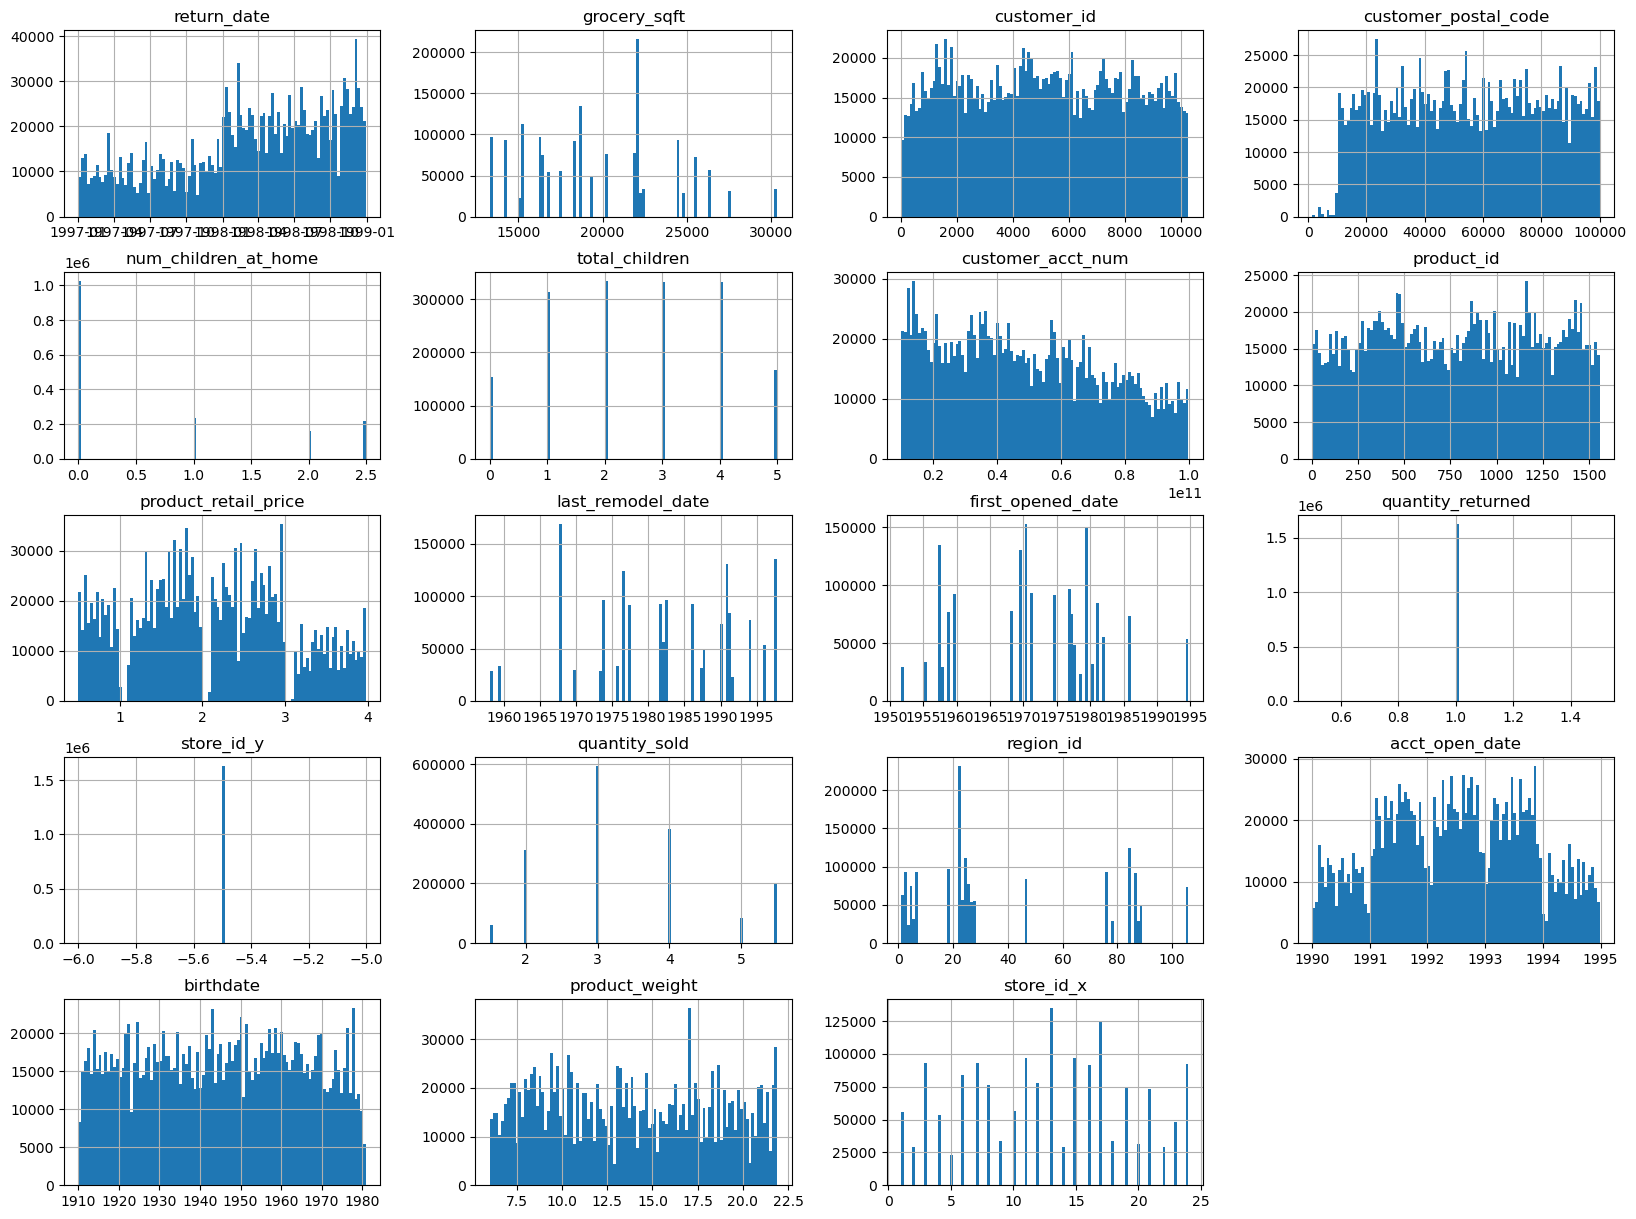

In [132]:
sales[num_cols].hist(bins= 100, figsize=(20, 15));

Encoding and normlization

In [142]:
num_cols = list(set(sales.describe().columns.to_list()))
cat_cols = list(set(sales.columns.to_list()))

In [145]:
from sklearn.preprocessing import LabelEncoder

label_encoders = {}

for col in cat_cols:
    label_encoders[col] = LabelEncoder()
    sales[col] = label_encoders[col].fit_transform(sales[col])

In [146]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

sales = pd.DataFrame(scaler.fit_transform(sales), columns=sales.columns)

In [147]:
sales

,transaction_date,stock_date,product_id,customer_id,store_id_x,quantity_sold,customer_acct_num,first_name,last_name,customer_address,...,store_country,store_phone,first_opened_date,last_remodel_date,grocery_sqft,sales_district,sales_region,return_date,store_id_y,quantity_returned
0,0.000000,0.008174,0.557125,0.334276,0.217391,0.8,0.241176,0.531905,0.938968,0.960462,...,1.0,0.956522,0.869565,0.826087,0.173913,0.3,1.000000,0.000000,0.0,0.0
1,0.000000,0.008174,0.557125,0.334276,0.217391,0.8,0.241176,0.531905,0.938968,0.960462,...,1.0,0.956522,0.869565,0.826087,0.173913,0.3,1.000000,0.023988,0.0,0.0
2,0.000000,0.008174,0.557125,0.334276,0.217391,0.8,0.241176,0.531905,0.938968,0.960462,...,1.0,0.956522,0.869565,0.826087,0.173913,0.3,1.000000,0.047016,0.0,0.0
3,0.000000,0.008174,0.557125,0.334276,0.217391,0.8,0.241176,0.531905,0.938968,0.960462,...,1.0,0.956522,0.869565,0.826087,0.173913,0.3,1.000000,0.067549,0.0,0.0
4,0.000000,0.008174,0.557125,0.334276,0.217391,0.8,0.241176,0.531905,0.938968,0.960462,...,1.0,0.956522,0.869565,0.826087,0.173913,0.3,1.000000,0.079064,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1632434,0.806172,0.502725,0.514763,0.205882,0.000000,0.8,0.112783,0.843333,0.229472,0.831313,...,0.5,0.217391,0.913043,0.782609,0.347826,0.0,0.666667,0.020150,0.0,0.0
1632435,0.806172,0.502725,0.514763,0.205882,0.000000,0.8,0.112783,0.843333,0.229472,0.831313,...,0.5,0.217391,0.913043,0.782609,0.347826,0.0,0.666667,0.025523,0.0,0.0
1632436,0.935391,0.501362,0.413992,0.205882,0.608696,0.6,0.112783,0.843333,0.229472,0.831313,...,1.0,0.869565,0.347826,0.260870,0.000000,0.7,0.833333,0.016887,0.0,0.0
1632437,0.935391,0.501362,0.413992,0.205882,0.608696,0.6,0.112783,0.843333,0.229472,0.831313,...,1.0,0.869565,0.347826,0.260870,0.000000,0.7,0.833333,0.058338,0.0,0.0


In [39]:
sales.columns

Index(['transaction_date', 'stock_date', 'product_id', 'customer_id',
       'store_id_x', 'quantity_x', 'customer_acct_num', 'first_name',
       'last_name', 'customer_address', 'customer_city',
       'customer_state_province', 'customer_postal_code', 'customer_country',
       'birthdate', 'marital_status', 'yearly_income', 'gender',
       'total_children', 'num_children_at_home', 'education', 'acct_open_date',
       'member_card', 'occupation', 'homeowner', 'product_brand',
       'product_name', 'product_sku', 'product_retail_price', 'product_cost',
       'product_weight', 'region_id', 'store_type', 'store_name',
       'store_street_address', 'store_city', 'store_state', 'store_country',
       'store_phone', 'first_opened_date', 'last_remodel_date', 'total_sqft',
       'grocery_sqft', 'sales_district', 'sales_region', 'return_date',
       'store_id_y', 'quantity_y'],
      dtype='object')